# **Full JEPA World Model Evaluation**
---

This notebook evaluates the full JEPA world model trained in `1-full_jepa_training.ipynb` (encoder and predictor trained jointly) with **exactly the same protocol** as the VAE world model in `notebooks/2-vae/4-vae_jepa_evaluation.ipynb`: same held-out test set, same probes, same metrics, same scorecard keys. Only the model-loading cell, the qualitative section and the interpretation differ. The full motivation of each test is kept below; see the VAE notebook for the history of the protocol decisions.

## **Protocol Recap**

$$z_t = \mathrm{Enc}(x_t), \qquad \hat{z}_{t+1} = f_\theta\big(z_{t-k+1:t},\ a_t\big)$$

1. **Fixed, held-out test set** (`data/eval/test_set.h5`, seeds disjoint from training).
2. **Frozen models**; only linear probes are fitted, on the probe half of the test episodes.
3. **Scale-free latent metrics** (skill vs. copy-last, NMSE), never raw MSE.
4. **Physical grounding** through linear probes to $(x, \dot{x}, \theta, \dot{\theta})$.
5. **Encoder vs. predictor**: every physical metric is paired with a probe **ceiling** on true latents.
6. **Causal action test** with simulator counterfactuals.

| Test | Question | Main metric |
|---|---|---|
| 0. Encoder diagnostics | How much state information does the latent space hold? | Effective dimension, probe ceiling R² |
| 1. One-step prediction | Does the predictor beat "nothing changes"? | Skill vs. copy-last, NMSE |
| 2. Action conditioning | Does the predictor know *what the action does*? | Effect skill, effect in physical units |
| 3. Latent rollouts | How fast do imagined trajectories drift? | Skill and NMSE vs. horizon |
| 4. Physical-state rollouts | How accurate are imagined states in physical units? | State RMSE vs. horizon (**primary**) |
| 5. Qualitative | What do the predictions look like? | Decoded frames (decoder of `2-latent_decoder.ipynb`) |

## **What Is Different for a JEPA Encoder**

- The encoder is **deterministic**: there is no $\log\sigma^2$, so the active-dimension count and noise floor of Test 0 are not reported.
- The encoder is the **EMA target encoder** (`FullJEPA.encode`), the space the predictor was trained to output.
- The latent space was shaped **for predictability**, not reconstruction. Two consequences to keep in mind: the VICReg terms spread information over more dimensions than the VAE (higher effective dimension, so the 99%-variance probe uses more components), and the scale of the latents is arbitrary — which the protocol already handles, since no raw latent MSE is compared across encoders.

## **Setup and Configuration**
---

In [1]:
from jepacartpole.evaluation import (
    generate_test_set, load_test_set, STATE_NAMES,
    load_world_model, encode_frames,
    fit_state_probe, probe_ceiling,
    encoder_diagnostics, one_step_metrics, rollout_metrics, counterfactual_metrics,
    plot_state_distribution, plot_encoder_diagnostics, plot_one_step,
    plot_latent_rollout, plot_state_rollout, plot_state_trajectories,
    plot_counterfactual, plot_decoded_rollout, plot_decoded_counterfactual,
    build_scorecard, save_scorecard, load_scorecards
)
from jepacartpole.full_jepa import load_full_jepa, load_latent_decoder
from jepacartpole.utils import get_device, set_seed, get_checkpoint_dir, get_data_dir

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

set_seed(42)
DEVICE = get_device()
print(f"Device: {DEVICE}")

Device: cuda


In [2]:
# Identification of the evaluated world model (used for the scorecard file name)
RUN_NAME = 'full-jepa-z32'
ENCODER_TYPE = 'JEPA encoder (EMA target), trained jointly with the predictor (EMA + VICReg)'

# Checkpoints produced by 1-full_jepa_training.ipynb and 2-latent_decoder.ipynb
JEPA_CHECKPOINT = get_checkpoint_dir() / 'full_jepa.pth'
DECODER_CHECKPOINT = get_checkpoint_dir() / 'latent_decoder.pth'

# Held-out test set (generated once, shared by all world models)
TEST_SET_PATH = get_data_dir('eval') / 'test_set.h5'

# Rollout horizon (sub-episodes are ~10 steps long, so longer horizons have very few segments)
HORIZON = 8

model, jepa_ckpt = load_full_jepa(JEPA_CHECKPOINT, DEVICE)
encoder = model                # model.encode(x) uses the EMA target encoder
predictor = model.predictor
CONTEXT_LEN = predictor.context_len

print(f"Run: {RUN_NAME}  ({ENCODER_TYPE})")
print(f"Config: {jepa_ckpt['config']}")
print(f"Trained epochs: {jepa_ckpt['epoch'] + 1}  |  final val skill: {jepa_ckpt['history']['val_skill'][-1]:.4f}")

Run: full-jepa-z32  (JEPA encoder (EMA target), trained jointly with the predictor (EMA + VICReg))
Config: ConfigFullJEPA(latent_dim=32, image_channels=3, context_len=2, hidden_dim=128, action_dim=1, batch_size=256, epochs=30, learning_rate=0.0003, weight_decay=1e-05, ema_momentum=0.99, ema_momentum_end=0.99, pred_weight=25.0, var_weight=25.0, cov_weight=1.0, var_gamma=1.0, expander_dim=256, val_fraction=0.1)
Trained epochs: 30  |  final val skill: 0.7678


## **Test Set**
---

The test set is generated once with `generate_test_set` and reused for every world model. It contains:

- **100 episodes × 500 steps** collected with the training policy (random action held for 20 steps, reset when the pole falls), seeds `100000 + i` (training used `42 + i`, i < 500).
- The **true physical state** $s_t = (x, \dot{x}, \theta, \dot{\theta})$ of every frame, read from the simulator (`env.unwrapped.state`). The training data has no states; here they are the ground truth for the physical metrics.
- **Counterfactual futures**: every 5 steps, the simulator is restored to the current state and run for 8 steps with action 0 held, and again with action 1 held, rendering every frame. These give the true effect of the action from the same starting state (Test 2).

The episodes are split in two halves: the **probe half** (episodes 0–49) is only used to fit the linear state probes; all metrics are computed on the **evaluation half** (episodes 50–99).

✅ Found existing test set: /teamspace/studios/this_studio/jepa_cart_pole/data/eval/test_set.h5 (use overwrite=True to regenerate)
Frames: (100, 500, 64, 64, 3)  |  resets: 4,793
Counterfactual starts: 6,144 × 2 actions × 8 steps
Probe episodes: 0–49  |  evaluation episodes: 50–99


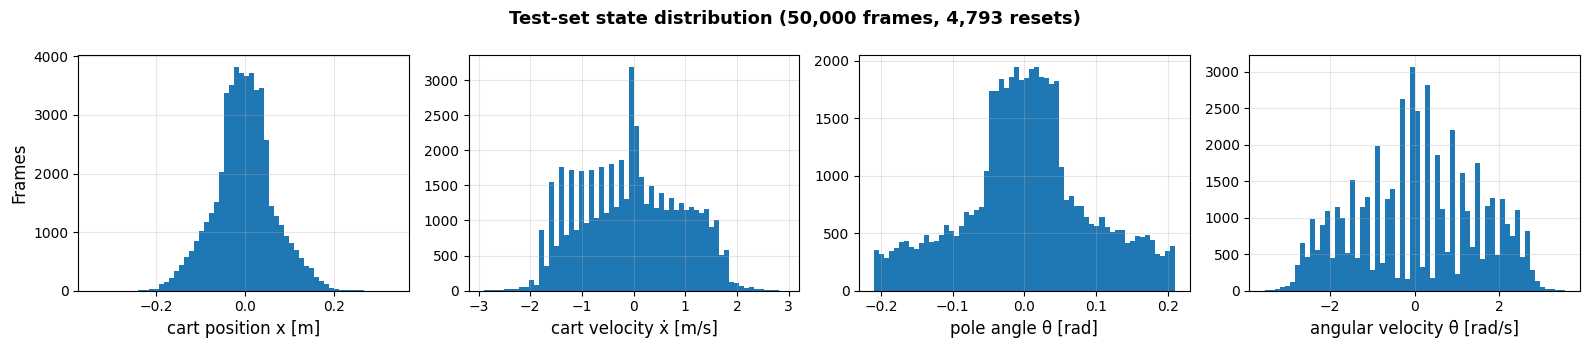

CPU times: user 1.29 s, sys: 2.44 s, total: 3.73 s
Wall time: 6.14 s


In [3]:
%%time
TEST_SET_PATH = generate_test_set(TEST_SET_PATH)   # skipped if it already exists
test = load_test_set(TEST_SET_PATH)

num_episodes = test['images'].shape[0]
PROBE_EPISODES = np.arange(num_episodes // 2)
EVAL_EPISODES = np.arange(num_episodes // 2, num_episodes)

print(f"Frames: {test['images'].shape}  |  resets: {test['dones'].sum():,}")
print(f"Counterfactual starts: {len(test['cf_starts']):,} × 2 actions × {test['cf_images'].shape[2]} steps")
print(f"Probe episodes: {PROBE_EPISODES[0]}–{PROBE_EPISODES[-1]}  |  evaluation episodes: {EVAL_EPISODES[0]}–{EVAL_EPISODES[-1]}")

fig = plot_state_distribution(test['states'], test['dones'])
plt.show()

### **Encoding the Test Set**

All test frames (and counterfactual frames) are encoded once with the frozen target encoder. The JEPA encoder is deterministic, so `logvar` is `None`.

In [4]:
%%time
z, logvar = encode_frames(encoder, test['images'], device=DEVICE)
z_cf, _ = encode_frames(encoder, test['cf_images'], device=DEVICE)
print(f"Latents: {z.shape}  |  counterfactual latents: {z_cf.shape}")

Latents: (100, 500, 32)  |  counterfactual latents: (6144, 2, 8, 32)
CPU times: user 6.76 s, sys: 4.76 s, total: 11.5 s
Wall time: 7.84 s


## **Test 0 - Encoder Diagnostics**
---

Before evaluating predictions, we characterise the latent space itself. These numbers describe the **encoder**, and bound what any predictor built on it can achieve.

**Effective dimension.** With $\lambda_i$ the eigenvalues of the latent covariance matrix, the *participation ratio*

$$d_{\text{eff}} = \frac{\left(\sum_i \lambda_i\right)^2}{\sum_i \lambda_i^2}$$

counts how many directions carry substantial variance ($d_{\text{eff}} = d$ if the variance is spread evenly, $d_{\text{eff}} = 1$ if it lies on a single direction). It is invariant to rotations and to the overall scale, so it can be compared across encoders. For VAEs we also report the number of **active dimensions** (mean KL to the prior > 0.05) and the **noise floor** $\overline{\sigma^2}$, the variance of sampled latents.

**State probes.** A *probe* is a simple model trained to read a quantity from a representation. We fit one linear (ridge) regression from two consecutive latents to the four state variables:

$$\hat{s}_t = W\,[z_t,\ z_{t-1}] + b$$

Two latents are needed because velocities are not visible in a single frame. A **linear** probe is used on purpose: it can only read information that is *explicitly* present in the latents, the form that is easiest for a predictor to use. To be fair to any latent space, the probe:

- projects each latent on its **principal subspace**, the smallest number of principal components explaining 99% of the latent variance;
- standardises the resulting features and chooses the ridge strength by cross-validation.

**Why the principal subspace?** On true latents, directions with almost no variance can add a little state information (the probe ceiling rises slightly), but a predictor's errors in those directions are as large as the signal itself. A probe that relies on them turns tiny latent errors into large state errors and stops measuring the quality of the prediction. In a first version of this protocol, the full 32-dimensional probe gave the JEPA a one-step error in $\dot{x}$ *worse* than the constant-state baseline, while the principal-subspace probe puts it close to the ceiling. The threshold is defined by variance, not by a number of dimensions, so it applies unchanged to any encoder.

The probe is fitted on the true latents of the probe episodes and evaluated on the evaluation episodes. Its R² is the **probe ceiling**: the physical accuracy obtained from the *true* latents, i.e. the accuracy a perfect predictor would reach through this encoder and this probe. (It is a reference level rather than a strict bound: a predictor outputs a conditional mean and can average out frame-level encoding noise, landing slightly below the ceiling error, as happens for the velocities at h = 1 in Test 4.) It is the first entry of the comparison between encoders.

Latent dimension:    32
Effective dimension: 24.39
Probe components:    29 (explaining 99.23% of the variance)

Probe ceiling (R² on evaluation episodes, true latents):
  x          0.5094
  x_dot      0.4069
  theta      0.6543
  theta_dot  0.4365


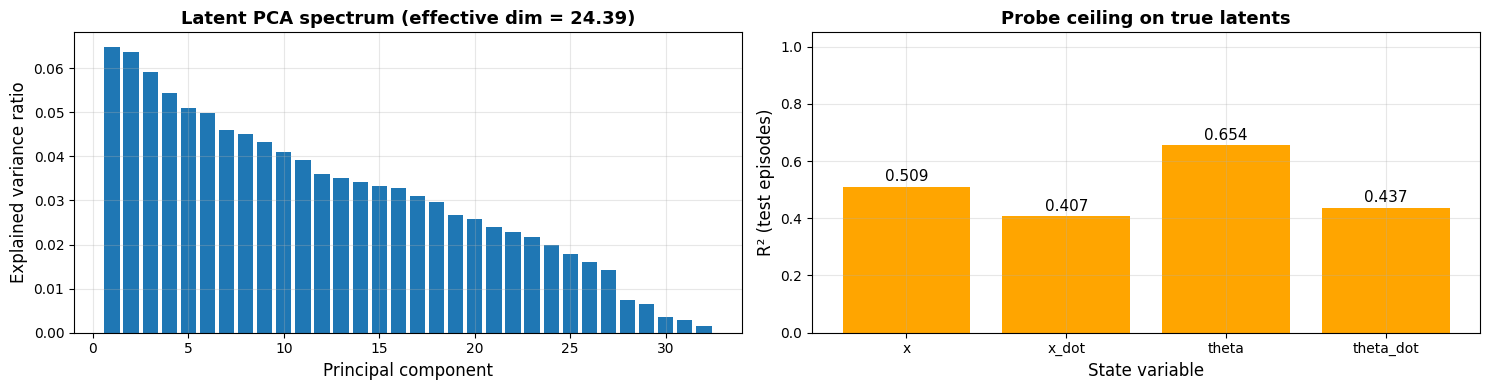

In [5]:
diag = encoder_diagnostics(z, logvar)
probe = fit_state_probe(z, test['states'], test['dones'], PROBE_EPISODES)
ceiling = probe_ceiling(probe, z, test['states'], test['dones'], EVAL_EPISODES)

print(f"Latent dimension:    {diag['latent_dim']}")
print(f"Effective dimension: {diag['effective_dim']:.2f}")
print(f"Probe components:    {probe[0].n_components_} (explaining {probe[0].explained_variance_:.2%} of the variance)")
if 'active_dims' in diag:
    print(f"Active dimensions:   {diag['active_dims']} (KL > 0.05)")
    print(f"Noise floor (mean σ²): {diag['noise_floor']:.3f}")
print()
print("Probe ceiling (R² on evaluation episodes, true latents):")
for name, r2 in zip(STATE_NAMES, ceiling):
    print(f"  {name:10s} {r2:.4f}")

fig = plot_encoder_diagnostics(diag, ceiling)
plt.show()

## **Test 1 - One-Step Prediction**
---

Consecutive CartPole frames are almost identical, so a predictor that simply copies its input already has a small error. The reference is therefore the **copy-last baseline** $\hat{z}_{t+1} = z_t$, and the main metric is the **skill score**, standard in forecasting:

$$\text{skill} = 1 - \frac{\mathrm{MSE}(\hat{z}_{t+1}, z_{t+1})}{\mathrm{MSE}(z_t, z_{t+1})}$$

- skill = 1: perfect prediction; skill = 0: no better than "nothing changes"; skill < 0: worse than copying.
- It is a ratio of errors measured in the same space, so the scale of the latent space cancels out.

We also report the **normalised MSE**, the error relative to the spread of the latents,

$$\mathrm{NMSE} = \frac{\sum_j \mathrm{MSE}_j}{\sum_j \mathrm{Var}(z_j)},$$

which is 1 for a model that always predicts the mean latent. Both metrics are invariant to rotations and to a global rescaling of the latent space (not to arbitrary per-dimension rescaling, which is why the physical metrics of Test 4 are the primary comparison).

The per-dimension plot shows where the error is: dimensions that the encoder does not use are nearly constant and trivially predictable; the dynamics live in the informative ones.

Finally, the one-step predictions are also converted to physical states with the probe (see Test 4 for the details), over **all** transitions: this is the one-step error in metres and radians, next to the probe ceiling and the constant-state baseline.

Transitions evaluated: 20,133
Skill vs. copy-last:   0.7634
NMSE (JEPA):           0.30914
NMSE (copy-last):      1.30642


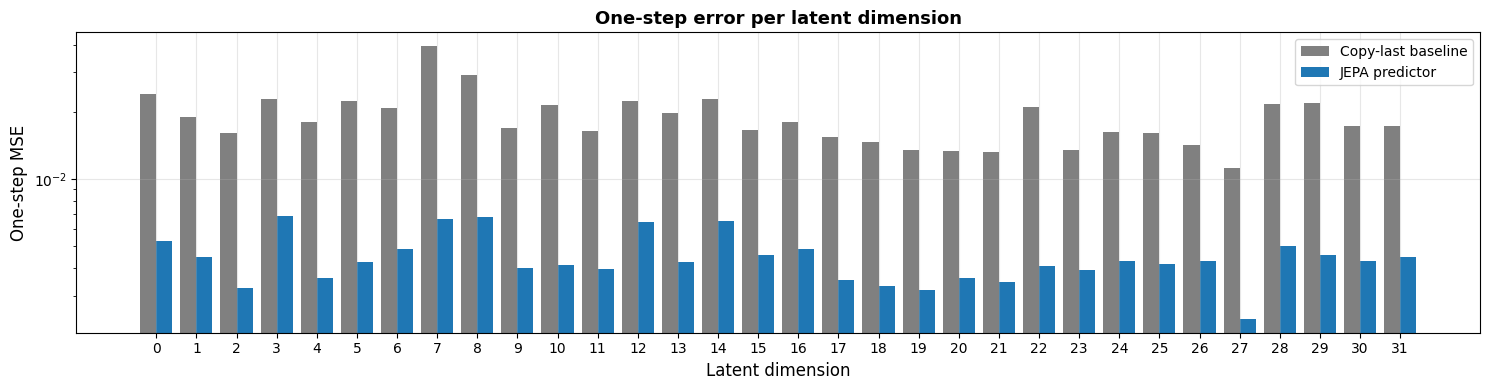

,JEPA,ceiling,constant state
one-step RMSE,,,
x,0.0462,0.0493,0.0562
x_dot,0.7886,0.8243,0.9248
theta,0.0522,0.0555,0.0675
theta_dot,1.1478,1.2029,1.3631


In [6]:
one_step = one_step_metrics(predictor, z, test['actions'], test['dones'], CONTEXT_LEN, DEVICE, EVAL_EPISODES)

print(f"Transitions evaluated: {one_step['n']:,}")
print(f"Skill vs. copy-last:   {one_step['skill']:.4f}")
print(f"NMSE (JEPA):           {one_step['nmse']:.5f}")
print(f"NMSE (copy-last):      {one_step['nmse_copy']:.5f}")

active = diag['kl_per_dim'] > 0.05 if 'kl_per_dim' in diag else None
fig = plot_one_step(one_step, active)
plt.show()

# One-step error in physical units, over all transitions
one_step_state = rollout_metrics(predictor, z, test['actions'], test['dones'], test['states'], probe,
                                 CONTEXT_LEN, 1, DEVICE, EVAL_EPISODES)
display(pd.DataFrame({'JEPA': one_step_state['state_rmse'][0],
                      'ceiling': one_step_state['state_rmse_ceiling'][0],
                      'constant state': one_step_state['state_rmse_constant'][0]},
                     index=pd.Index(STATE_NAMES, name='one-step RMSE')).round(4))

## **Test 2 - Action Conditioning (Counterfactuals)**
---

A world model is only useful for planning or reinforcement learning if it predicts **how the future depends on the action**. A predictor can beat the copy-last baseline while ignoring the action entirely (by extrapolating the current motion), so prediction accuracy alone does not test this.

**Why naive tests fail here.** Two properties of the setting make simple tests misleading:

1. **Delayed effect.** CartPole integrates the dynamics with the explicit Euler method:
$$x_{t+1} = x_t + \tau\,\dot{x}_t, \qquad \dot{x}_{t+1} = \dot{x}_t + \tau\,\ddot{x}_t(a_t)$$
(and likewise for $\theta$). The positions at $t+1$ do not depend on $a_t$; only the velocities do. The frame $x_{t+1}$ is therefore **identical** for both actions, and the action first becomes visible at $t+2$, growing roughly quadratically with the horizon.
2. **Correlated actions.** The data policy holds each action for 20 steps, so $a_t = a_{t-1}$ about 95% of the time. Comparing the prediction with the observed future would mostly reward exploiting this correlation (the previous action is already visible in the motion), not understanding the action.

**Counterfactual test.** The test set contains true counterfactuals: from the same simulator state $s_t$, the future is rendered once with $a = 0$ held and once with $a = 1$ held for $H = 8$ steps. The predictor is rolled out from the same true context with each action sequence. With $\hat{z}^a_{t+h}$ the predictions and $z^a_{t+h}$ the encoded true frames, the true and predicted **effects of the action** are

$$D_{\text{true}}(h) = z^1_{t+h} - z^0_{t+h}, \qquad D_{\text{pred}}(h) = \hat{z}^1_{t+h} - \hat{z}^0_{t+h}.$$

- **Effect skill** $= 1 - \overline{\lVert D_{\text{pred}} - D_{\text{true}}\rVert^2} \,/\, \overline{\lVert D_{\text{true}}\rVert^2}$: 1 for a perfect model, **0 for an action-blind model** ($D_{\text{pred}} = 0$), negative if the predicted effect is wrong.
- **Cosine similarity** between $D_{\text{pred}}$ and $D_{\text{true}}$: is the effect predicted in the right direction?
- **Physical effect**: the probe converts both branches into states, giving the predicted difference in cart position and pole angle between the two actions, compared with the simulator's true difference and with the probe ceiling.

$h = 1$ is undefined ($D_{\text{true}} = 0$ by construction). Branches are only used while the pole has not fallen, so the number of starts decreases with $h$.

,starts,effect skill,cosine,Δx true [m],Δx pred [m],Δθ true [rad],Δθ pred [rad]
h,,,,,,,
1,3073,NaN,NaN,0.0000,0.0150,0.0000,0.0196
2,2561,-0.8010,0.1683,0.0078,0.0292,0.0117,0.0402
3,2086,-0.2085,0.1949,0.0234,0.0414,0.0350,0.0620
4,1637,-0.1811,0.1519,0.0468,0.0412,0.0701,0.0685
5,1157,-0.2353,0.0902,0.0780,0.0308,0.1171,0.0631
6,666,-0.3291,0.0444,0.1171,0.0224,0.1763,0.0610
7,333,-0.2778,0.0839,0.1639,0.0213,0.2478,0.0601
8,179,-0.2809,0.0905,0.2187,0.0197,0.3321,0.0591


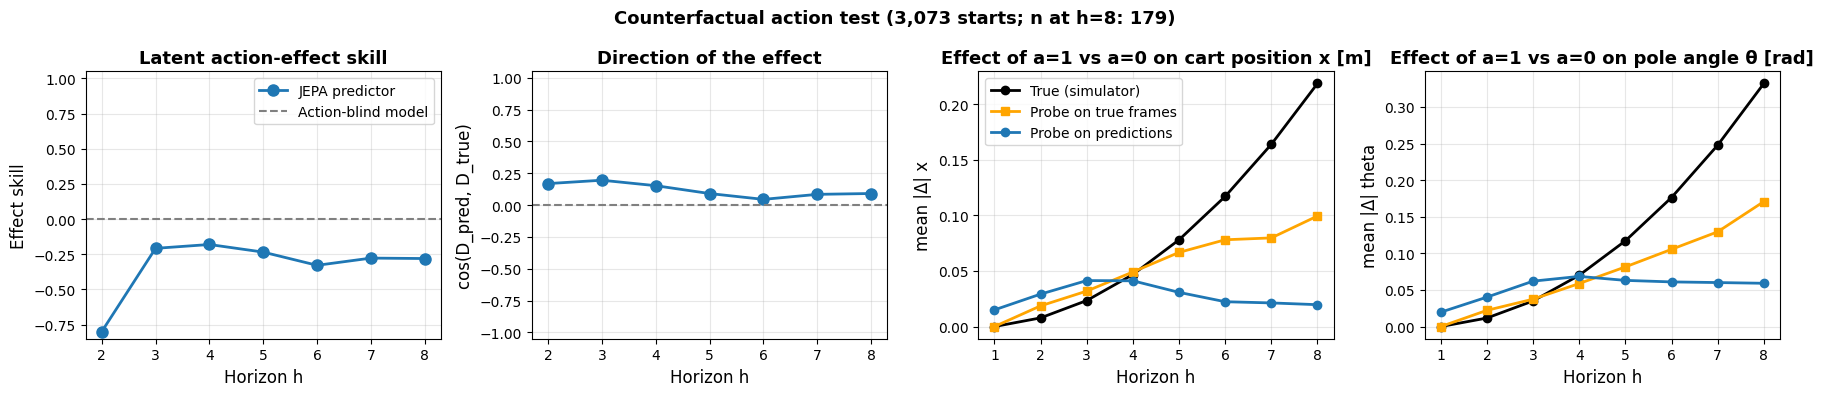

In [7]:
cf = counterfactual_metrics(predictor, z, z_cf, test['cf_starts'], test['cf_valid'], test['cf_states'],
                            probe, CONTEXT_LEN, DEVICE, EVAL_EPISODES)

table = pd.DataFrame({
    'starts': cf['n_per_h'],
    'effect skill': cf['effect_skill'],
    'cosine': cf['cosine'],
    'Δx true [m]': cf['state_effect_true'][:, 0],
    'Δx pred [m]': cf['state_effect_pred'][:, 0],
    'Δθ true [rad]': cf['state_effect_true'][:, 2],
    'Δθ pred [rad]': cf['state_effect_pred'][:, 2],
}, index=pd.Index(np.arange(1, cf['horizon'] + 1), name='h'))
display(table.round(4))

fig = plot_counterfactual(cf)
plt.show()

## **Test 3 - Open-Loop Latent Rollouts**
---

For planning, the model must *imagine* several steps ahead without seeing new frames. In an **open-loop rollout** the predictions are fed back as context while the recorded actions are applied:

$$\hat{z}_{t+h+1} = f_\theta\big(\hat{z}_{t+h-k+1:t+h},\ a_{t+h}\big), \qquad h = 1, \dots, H-1$$

Each step adds error that is propagated by the following steps (**compounding error**), so the error grows with the horizon. We report the skill score and the NMSE at each horizon $h$, relative to the copy-last baseline $\hat{z}_{t+h} = z_t$. A good world model keeps a positive skill over the whole horizon; the horizon at which skill reaches 0 is how far ahead the model is useful.

All segments are taken inside a single sub-episode (no reset between $t-k+1$ and $t+H$). With random actions the pole falls every ~10 steps, which limits the horizon to $H = 8$.

**Selection effect.** Requiring $H$ reset-free steps after $t$ means that most segments start shortly after a reset, when the cart and pole are still moving slowly. On this subset copying the last latent is an unusually good prediction, so the $h = 1$ values here are lower than the one-step skill of Test 1, which uses every transition. Values at different horizons are comparable with each other, and across encoders, because every model is evaluated on the same segments.

Segments evaluated: 3,530


,skill,NMSE,NMSE copy-last
h,,,
1,0.3648,0.4366,0.6874
2,0.4547,0.6607,1.2115
3,0.4436,0.8201,1.4740
4,0.4043,0.9931,1.6672
5,0.3780,1.1481,1.8457
6,0.3385,1.3095,1.9796
7,0.3015,1.4021,2.0073
8,0.3043,1.3845,1.9901


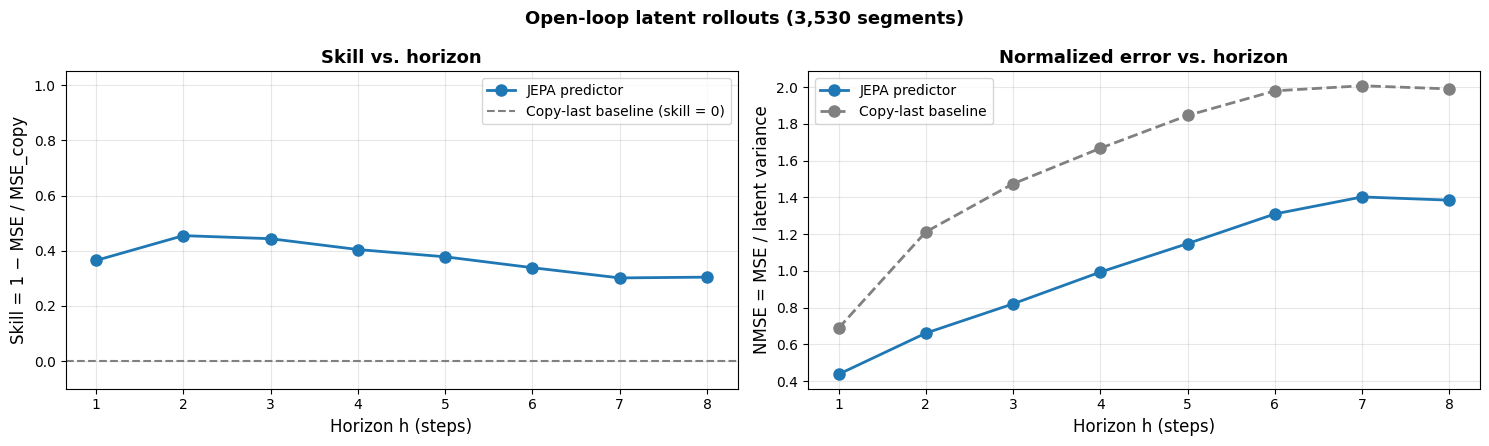

In [8]:
roll = rollout_metrics(predictor, z, test['actions'], test['dones'], test['states'], probe,
                       CONTEXT_LEN, HORIZON, DEVICE, EVAL_EPISODES)

print(f"Segments evaluated: {roll['n']:,}")
display(pd.DataFrame({'skill': roll['skill'], 'NMSE': roll['nmse'], 'NMSE copy-last': roll['nmse_copy']},
                     index=pd.Index(np.arange(1, HORIZON + 1), name='h')).round(4))

fig = plot_latent_rollout(roll)
plt.show()

## **Test 4 - Physical-State Rollouts**
---

This is the **primary comparison between encoders**. The probe of Test 0 (fitted only on true latents of the probe episodes, never on predictions) converts every imagined latent pair $[\hat{z}_{t+h}, \hat{z}_{t+h-1}]$ into a physical state, which is compared with the simulator's true state $s_{t+h}$:

$$\mathrm{RMSE}_i(h) = \sqrt{\overline{\big(\hat{s}_{t+h,i} - s_{t+h,i}\big)^2}}, \qquad i \in \{x, \dot{x}, \theta, \dot{\theta}\}$$

The errors are in metres, m/s, radians and rad/s, whatever the encoder. Each curve is shown with two references:

- **Ceiling** — the probe applied to the *true* future latents: the error caused by the encoder and the probe alone, i.e. what a perfect predictor would achieve. It is a reference level, not a strict bound (a predictor can average out per-frame encoding noise and fall slightly below it).
- **Constant state** — the state estimated at time $t$ held constant, the copy-last baseline expressed in physical units.

Reading: the distance between ceiling and constant state is the room for improvement; where the JEPA curve lies in between shows how much of it the predictor captures. Comparing two encoders, a better ceiling means a more informative latent space, and a smaller gap to the ceiling means more predictable latent dynamics.

JEPA  ceiling  constant state  R² JEPA
h variable                                           
1 x          0.0428   0.0470          0.0473   0.2397
  x_dot      0.7403   0.8280          0.8434  -1.3302
  theta      0.0491   0.0530          0.0539   0.5277
  theta_dot  1.0564   1.1886          1.2116  -1.5409
4 x          0.0515   0.0487          0.0597   0.1521
  x_dot      1.0081   1.0402          1.2336  -0.3863
  theta      0.0651   0.0551          0.0744   0.2084
  theta_dot  1.4100   1.4586          1.7581  -0.4371
8 x          0.1098   0.0688          0.1235   0.0484
  x_dot      1.4888   1.1964          1.8545   0.0069
  theta      0.1400   0.0748          0.1687   0.0017
  theta_dot  2.1364   1.6496          2.6990   0.0110

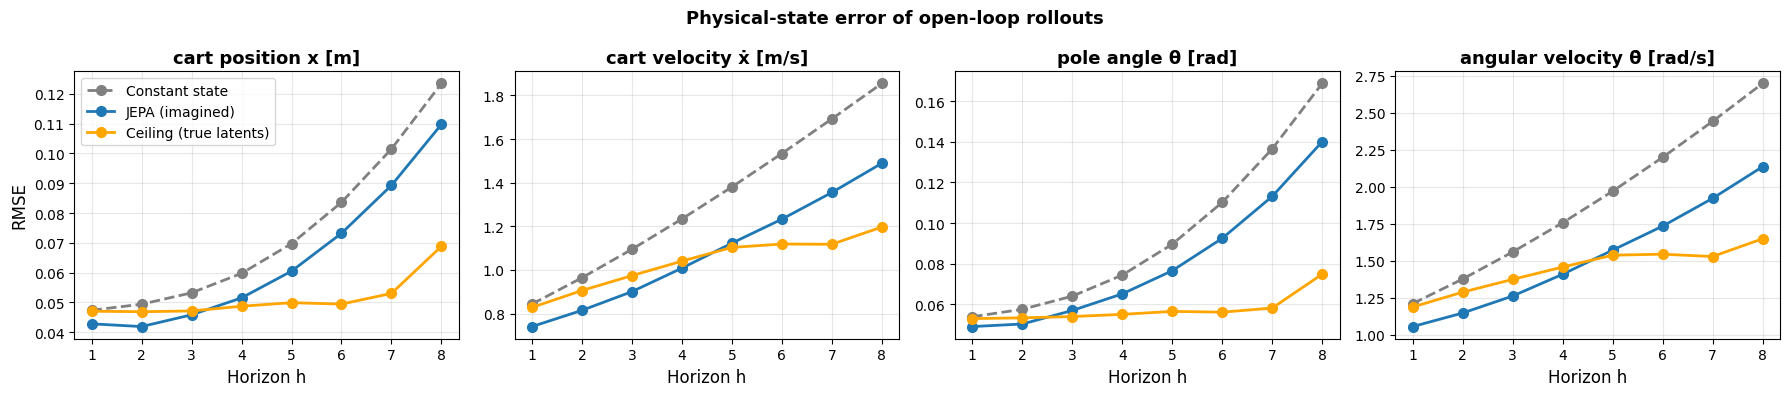

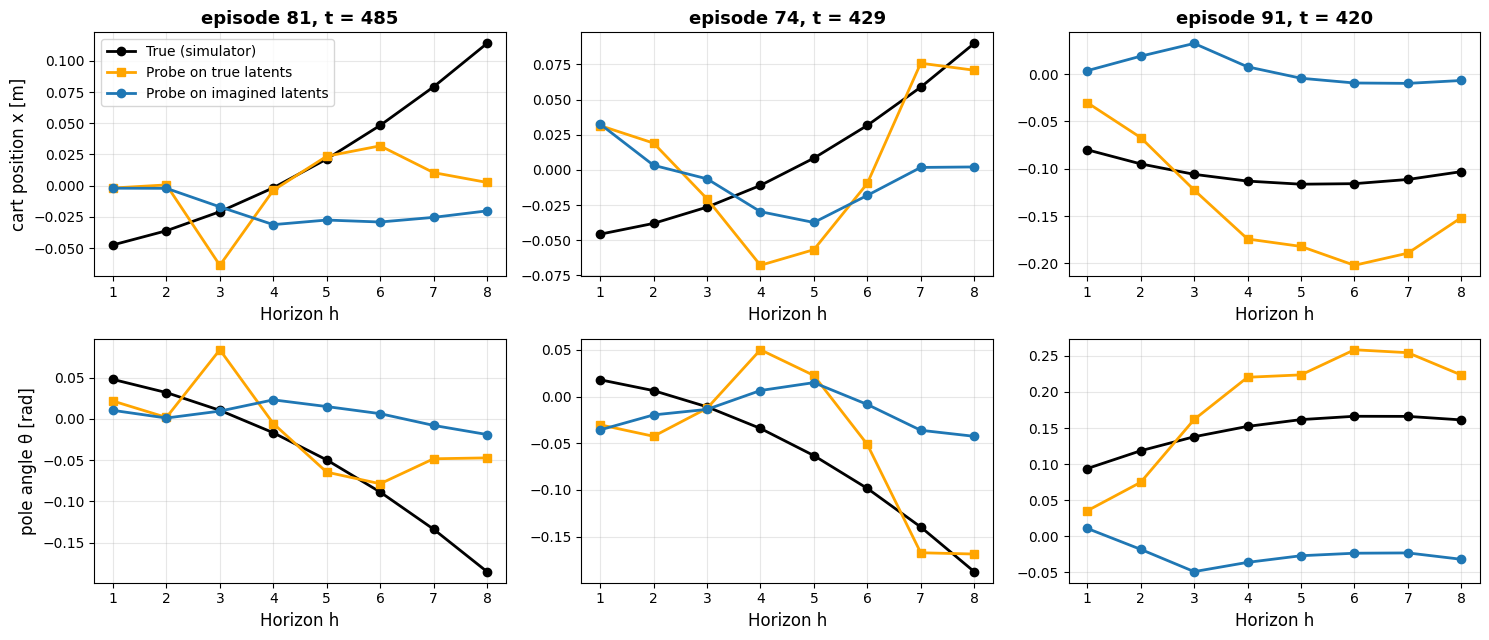

In [9]:
rows = []
for h in (1, 4, HORIZON):
    for i, name in enumerate(STATE_NAMES):
        rows.append({'h': h, 'variable': name,
                     'JEPA': roll['state_rmse'][h - 1, i],
                     'ceiling': roll['state_rmse_ceiling'][h - 1, i],
                     'constant state': roll['state_rmse_constant'][h - 1, i],
                     'R² JEPA': roll['state_r2'][h - 1, i]})
display(pd.DataFrame(rows).set_index(['h', 'variable']).round(4))

fig = plot_state_rollout(roll)
plt.show()
fig = plot_state_trajectories(roll, n=3)
plt.show()

## **Test 5 - Qualitative Inspection (Latent Decoder)**
---

The JEPA has no decoder of its own. The decoder trained afterwards on the frozen latents (`2-latent_decoder.ipynb`) turns imagined latents back into images. This is only a visual aid: decoded images mix predictor errors with decoder errors, and the decoder can only show what it learned to read from the latents. The section is skipped if the decoder has not been trained.

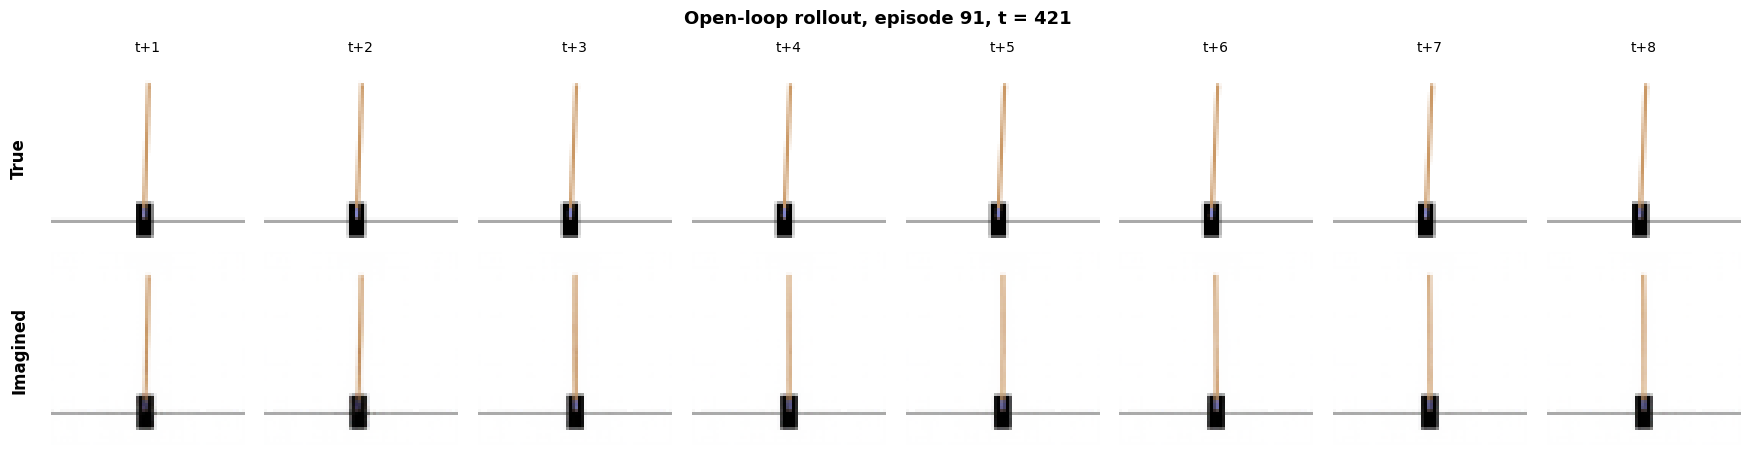

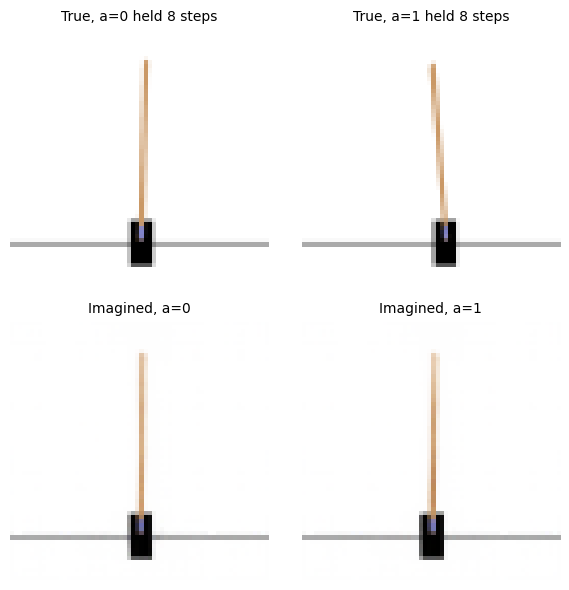

In [10]:
if DECODER_CHECKPOINT.exists():
    decoder, _ = load_latent_decoder(DECODER_CHECKPOINT, DEVICE)
    fig = plot_decoded_rollout(decoder, roll, test['images'], n_steps=HORIZON)
    plt.show()
    fig = plot_decoded_counterfactual(decoder, cf, test['cf_starts'], test['cf_images'])
    plt.show()
else:
    print("No latent decoder checkpoint: qualitative section skipped (run 2-latent_decoder.ipynb).")

## **Scorecard**
---

The headline metrics of this run are saved to `results/eval/<RUN_NAME>.json`. Every world model evaluated with this notebook writes the same keys, so the table below compares all saved runs side by side. The physical-state RMSE of the constant-state baseline is included so that each run can be read against its own reference.

In [11]:
card = build_scorecard(RUN_NAME, ENCODER_TYPE, diag, ceiling, one_step, roll, cf, one_step_state, probe)
path = save_scorecard(card)
print(f"Scorecard saved to: {path}\n")

comparison = load_scorecards()
display(comparison)

Scorecard saved to: /teamspace/studios/this_studio/jepa_cart_pole/results/eval/full-jepa-z32.json



run_name,full-jepa-z32,vae-z32
encoder_type,"JEPA encoder (EMA target), trained jointly wit...","ConvVAE (World Models), trained from scratch"
date,2026-10-12,2026-10-08
notes,,
latent_dim,32,32
effective_dim,24.389,2.086
active_dims,NaN,4.0
probe_components,29,3
one_step_skill,0.7634,0.8873
one_step_nmse,0.30914,0.00848
probe_ceiling_r2_x,0.5094,0.9908


### **Interpretation**

*To be filled after running the evaluation.*